<a href="https://colab.research.google.com/github/jpozoarroyo-dot/Mesa-Partes-Sismos/blob/main/Mesa_Partes_Simos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


   MESA DE PARTES DIGITAL - SISMO
1. Registrar ciudadano afectado
2. Buscar reporte
3. Ordenar expedientes por urgencia
4. Generar gráfico de evaluación
5. Descargar Archivo (TXT/Excel)
6. Guardar y Salir
Seleccione una opción (1-6): 1

--- NUEVO REGISTRO ---
Ingrese DNI (8 dígitos): 483200845
Error: El DNI debe contener exactamente 8 números.
Ingrese DNI (8 dígitos): 48320084
Ciudadano encontrado en BD: JESUS POZO ARROYO
Ingrese Teléfono (9 dígitos): 926269561
Dirección (Distrito y Calle): Ate

Tipos de solicitud:
1. Rescate y Atrapamiento
2. Atención Médica y Heridos
3. Suministros (Agua, Víveres)
4. Riesgos (Fuga Gas/Agua, Derrumbes)
5. Refugio Temporal
6. Otros
Seleccione el tipo (1-6): 2

Nivel de urgencia (1=Alta, 2=Media, 3=Baja): 2

Reporte registrado con éxito. Código asignado: EXP0001

   MESA DE PARTES DIGITAL - SISMO
1. Registrar ciudadano afectado
2. Buscar reporte
3. Ordenar expedientes por urgencia
4. Generar gráfico de evaluación
5. Descargar Archivo (TXT/Excel)
6. Gua

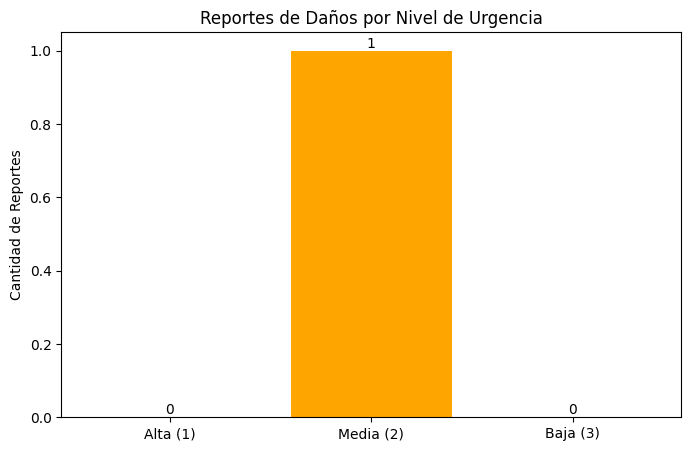


   MESA DE PARTES DIGITAL - SISMO
1. Registrar ciudadano afectado
2. Buscar reporte
3. Ordenar expedientes por urgencia
4. Generar gráfico de evaluación
5. Descargar Archivo (TXT/Excel)
6. Guardar y Salir


In [ ]:
# ==========================================================
# PROYECTO: MESA DE PARTES DIGITAL - SISMO
# CURSO: Fundamentos de Programación
# ==========================================================

import os
import matplotlib.pyplot as plt # Librería para generar graficos estadisticos.
from datetime import datetime  # Proporciona clases para manipular fechas y horas.
from google.colab import files # Librería exclusiva para descargas en Colab

# --- ARREGLOS PARALELOS PRINCIPALES ---
codigos = []
dnis = []
nombres = []
telefonos = []
direcciones = []
tipos = []
urgencias = []
fechas = []

ARCHIVO = "reportes_sismo.txt"

# --- ARREGLOS PARA LA BASE DE DATOS EXTERNA ---
bd_dnis = []
bd_nombres = []
ARCHIVO_BD = "ReniecBD.txt"

# --- MÓDULOS DE VALIDACIÓN ---
def leer_dni():
    while True:
        dni = input("Ingrese DNI (8 dígitos): ").strip()
        if dni.isdigit() and len(dni) == 8:
            return dni
        print("Error: El DNI debe contener exactamente 8 números.")

def leer_telefono():
    while True:
        tel = input("Ingrese Teléfono (9 dígitos): ").strip()
        if tel.isdigit() and len(tel) == 9:
            return tel
        print("Error: El teléfono debe contener exactamente 9 números.")

def leer_solo_texto(mensaje):
    while True:
        texto = input(mensaje).strip()
        if texto.replace(" ", "").isalpha():
            return texto.upper()
        print("Error: Ingrese solo letras, sin números ni caracteres especiales.")

def leer_entero(mensaje, minimo, maximo):
    while True:
        valor = input(mensaje).strip()
        if valor.isdigit():
            numero = int(valor)
            if minimo <= numero <= maximo:
                return numero
        print(f"Error: Ingrese un número válido entre {minimo} y {maximo}.")

# --- MÓDULOS DE PERSISTENCIA ---
def cargar_bd():
    if os.path.exists(ARCHIVO_BD):
        with open(ARCHIVO_BD, "r", encoding="utf-8") as archivo:
            lineas = archivo.readlines()
            if len(lineas) > 1:
                for linea in lineas[1:]:
                    datos = linea.rstrip("\n").split("|")
                    if len(datos) == 2:
                        bd_dnis.append(datos[0])
                        bd_nombres.append(datos[1])

def cargar_datos():
    if os.path.exists(ARCHIVO):
        with open(ARCHIVO, "r", encoding="utf-8") as archivo:
            lineas = archivo.readlines()
            if len(lineas) > 1:
                for linea in lineas[1:]:
                    datos = linea.rstrip("\n").split("|")
                    if len(datos) == 8: # Actualizado a 8 campos
                        codigos.append(datos[0])
                        dnis.append(datos[1])
                        nombres.append(datos[2])
                        telefonos.append(datos[3])
                        direcciones.append(datos[4])
                        tipos.append(datos[5])
                        urgencias.append(int(datos[6]))
                        fechas.append(datos[7])

def guardar_datos():
    with open(ARCHIVO, "w", encoding="utf-8") as archivo:
        archivo.write("CÓDIGO|DNI|NOMBRE|TELÉFONO|DIRECCIÓN|TIPO|URGENCIA|FECHA\n")
        for i in range(len(codigos)):
            linea = f"{codigos[i]}|{dnis[i]}|{nombres[i]}|{telefonos[i]}|{direcciones[i]}|{tipos[i]}|{urgencias[i]}|{fechas[i]}\n"
            archivo.write(linea)

# --- MÓDULOS DEL ALGORITMO ---
def registrar_ciudadano():
    print("\n--- NUEVO REGISTRO ---")

    dni = leer_dni()
    nombre = ""

    encontrado_bd = False
    for i in range(len(bd_dnis)):
        if bd_dnis[i] == dni:
            nombre = bd_nombres[i]
            print(f"Ciudadano encontrado en BD: {nombre}")
            encontrado_bd = True
            break

    if not encontrado_bd:
        nombre = leer_solo_texto("Ingrese Nombres y Apellidos: ")

    telefono = leer_telefono()
    direccion = input("Dirección (Distrito y Calle): ").strip().upper()

    print("\nTipos de solicitud:")
    print("1. Rescate y Atrapamiento")
    print("2. Atención Médica y Heridos")
    print("3. Suministros (Agua, Víveres)")
    print("4. Riesgos (Fuga Gas/Agua, Derrumbes)")
    print("5. Refugio Temporal")
    print("6. Otros")
    opcion_tipo = leer_entero("Seleccione el tipo (1-6): ", 1, 6)
    lista_tipos = ["Rescate", "Médica", "Suministros", "Riesgos", "Refugio", "Otros"]
    tipo_elegido = lista_tipos[opcion_tipo - 1]

    urgencia = leer_entero("\nNivel de urgencia (1=Alta, 2=Media, 3=Baja): ", 1, 3)
    fecha_actual = datetime.now().strftime("%d/%m/%Y %H:%M")
    nuevo_codigo = f"EXP{len(codigos) + 1:04d}"

    codigos.append(nuevo_codigo)
    dnis.append(dni)
    nombres.append(nombre)
    telefonos.append(telefono)
    direcciones.append(direccion)
    tipos.append(tipo_elegido)
    urgencias.append(urgencia)
    fechas.append(fecha_actual)

    print(f"\nReporte registrado con éxito. Código asignado: {nuevo_codigo}")

def buscar_reporte():
    buscado = input("\nIngrese DNI o Código a buscar: ").strip().upper()
    encontrado = False

    for i in range(len(dnis)):
        if dnis[i] == buscado or codigos[i] == buscado:
            print("\n--- REPORTE ENCONTRADO ---")
            print(f"CÓDIGO: {codigos[i]}")
            print(f"URGENCIA: {urgencias[i]}")
            print(f"DNI: {dnis[i]}")
            print(f"NOMBRE: {nombres[i]}")
            print(f"TELÉFONO: {telefonos[i]}")
            print(f"TIPO: {tipos[i]}")
            print(f"DIRECCIÓN: {direcciones[i]}")
            print(f"FECHA Y HORA DE INGRESO: {fechas[i]}")
            print("=======================================")
            encontrado = True

    if not encontrado:
        print("No se encontró ningún reporte con esos datos.")

def ordenar_por_urgencia():
    print("\n--- ORDENAMIENTO ---")
    n = len(urgencias)
    if n == 0:
        print("No hay datos para ordenar.")
        return

    for i in range(n - 1):
        for j in range(n - i - 1):
            if urgencias[j] > urgencias[j+1]:
                urgencias[j], urgencias[j+1] = urgencias[j+1], urgencias[j]
                codigos[j], codigos[j+1] = codigos[j+1], codigos[j]
                dnis[j], dnis[j+1] = dnis[j+1], dnis[j]
                nombres[j], nombres[j+1] = nombres[j+1], nombres[j]
                telefonos[j], telefonos[j+1] = telefonos[j+1], telefonos[j]
                direcciones[j], direcciones[j+1] = direcciones[j+1], direcciones[j]
                tipos[j], tipos[j+1] = tipos[j+1], tipos[j]
                fechas[j], fechas[j+1] = fechas[j+1], fechas[j]

    print("Expedientes ordenados de Alta (1) a Baja (3) urgencia.")
    for i in range(n):
        print(f"Urgencia {urgencias[i]} - {codigos[i]} - DNI: {dnis[i]} - {nombres[i]}")

def generar_grafico():
    print("\n--- GENERANDO GRÁFICO ESTADÍSTICO ---")
    if len(urgencias) == 0:
        print("No hay reportes para graficar.")
        return

    alta, media, baja = 0, 0, 0
    for u in urgencias:
        if u == 1: alta += 1
        elif u == 2: media += 1
        elif u == 3: baja += 1

    plt.figure(figsize=(8, 5))
    barras = plt.bar(["Alta (1)", "Media (2)", "Baja (3)"], [alta, media, baja], color=['red', 'orange', 'green'])
    plt.title("Reportes de Daños por Nivel de Urgencia")
    plt.ylabel("Cantidad de Reportes")

    for barra in barras:
        altura = barra.get_height()
        plt.text(barra.get_x() + barra.get_width() / 2, altura, str(int(altura)), ha="center", va="bottom")
    plt.show()

def descargar_archivo():
    print("\n--- DESCARGAR REPORTES ---")
    print("1. Archivo de Texto (.txt)")
    print("2. Archivo CSV (Abre en Excel)")
    opcion = leer_entero("Seleccione formato (1-2): ", 1, 2)

    if opcion == 1:
        guardar_datos()
        print(f"Preparando descarga del archivo de texto...")
        files.download(ARCHIVO)

    elif opcion == 2:
        nombre_csv = "reportes_excel.csv"
        with open(nombre_csv, mode="w", encoding="utf-8-sig") as archivo_csv:
            archivo_csv.write("CÓDIGO;DNI;NOMBRE;TELÉFONO;DIRECCIÓN;TIPO;URGENCIA;FECHA\n")
            for i in range(len(codigos)):
                linea = f"{codigos[i]};{dnis[i]};{nombres[i]};{telefonos[i]};{direcciones[i]};{tipos[i]};{urgencias[i]};{fechas[i]}\n"
                archivo_csv.write(linea)

        print(f"Preparando descarga del archivo Excel...")
        files.download(nombre_csv)

# --- MENÚ PRINCIPAL ---
def menu_principal():
    cargar_bd()
    cargar_datos()
    while True:
        print("\n=======================================")
        print("   MESA DE PARTES DIGITAL - SISMO")
        print("=======================================")
        print("1. Registrar ciudadano afectado")
        print("2. Buscar reporte")
        print("3. Ordenar expedientes por urgencia")
        print("4. Generar gráfico de evaluación")
        print("5. Descargar Archivo (TXT/Excel)")
        print("6. Guardar y Salir")
        print("=======================================")

        opcion = input("Seleccione una opción (1-6): ").strip()

        if opcion == "1": registrar_ciudadano()
        elif opcion == "2": buscar_reporte()
        elif opcion == "3": ordenar_por_urgencia()
        elif opcion == "4": generar_grafico()
        elif opcion == "5": descargar_archivo()
        elif opcion == "6":
            guardar_datos()
            print("Datos guardados. Cerrando sistema...")
            break
        else:
            print("Opción inválida. Intente nuevamente.")

# Ejecución del programa principal
if __name__ == "__main__":
    menu_principal()